# GNN V1LD — Test d'inférence

Compare sur un nœud B&B :
- **L1(λ=0)** : borne sans optimisation
- **L1(λ_GNN)** : prédiction directe du modèle entraîné
- **L1(sous-gradient T=200)** : convergence complète (référence)
- **L1(sous-gradient warm-start)** : sous-gradient initialisé avec λ_GNN

Focus sur le **temps d'inférence** et la qualité de la borne.

In [1]:
import sys, pathlib
REPO = pathlib.Path(".").resolve().parent
sys.path.insert(0, str(REPO))

import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from gnn.train_gnn_v1ld import (
    load_instances, load_raw_nodes, LazyGraphDataset,
    GNN, lagrangian_v1ld, verify_v1ld, build_graph,
)

/home/romanlen/envs/learning_bounds/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[bnb_solver] C++ B&B chargé (solve_zeta_batch)


## Configuration

In [2]:
# ── Checkpoint ──────────────────────────────────────────────────────────────
CKPT_PATH = REPO / "results/train_base_n10_ep1_lr1e-3_h64/ckpt_train_base_n10_m5_maxN500_ep1_lr0.001_bs32_h64_seed42.pt"
M_CKPT    = 5    # nombre de contraintes du checkpoint
HIDDEN    = 64

# ── Dataset (pour sélectionner un nœud existant) ─────────────────────────────
INSTANCES_FILE = REPO / "data/train_base/instances_n10_m5.txt"
NODES_FILE     = REPO / "data/train_base/nodes_n10_m5.txt"

# ── Inférence ────────────────────────────────────────────────────────────────
DEVICE   = "cpu"   # inférence CPU pour mesurer les vrais temps
N_RUNS   = 30      # répétitions pour le timing GNN
T_SG     = 200     # itérations sous-gradient

## Chargement du modèle

In [3]:
device = torch.device(DEVICE)

ckpt  = torch.load(CKPT_PATH, map_location=device)
model = GNN(m=M_CKPT, hidden=HIDDEN)
model.load_state_dict(ckpt["model"])
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"Checkpoint : {CKPT_PATH.name}")
print(f"Epoch      : {ckpt.get('epoch', '?')}")
print(f"Paramètres : {n_params:,}")

Checkpoint : ckpt_train_base_n10_m5_maxN500_ep1_lr0.001_bs32_h64_seed42.pt
Epoch      : 1
Paramètres : 176,449


## Chargement du dataset
Utilisé pour sélectionner un nœud B&B existant par index.

In [4]:
print("Chargement des nœuds...")
instances, raw_records = load_raw_nodes(str(INSTANCES_FILE), str(NODES_FILE))
dataset = LazyGraphDataset(instances, raw_records)

depths   = np.array([r["depth"] for r in raw_records])
inst_ids = np.array([r["inst_id"] for r in raw_records])
print(f"{len(instances)} instances  |  {len(raw_records)} nœuds")
print(f"Profondeur : min={depths.min()}  max={depths.max()}  moy={depths.mean():.1f}")
print(f"IDs instance : {inst_ids.min()} – {inst_ids.max()}")

# Index des nœuds par profondeur — utile pour choisir
by_depth = {d: np.where(depths == d)[0] for d in np.unique(depths)}
print("\nNœuds par profondeur :")
for d in sorted(by_depth)[:8]:
    print(f"  depth={d} : {len(by_depth[d])} nœuds (ex. idx={by_depth[d][0]})")

Chargement des nœuds...
[load_raw_nodes] 163349 enregistrements chargés, 4250 ignorés
862 instances  |  163349 nœuds
Profondeur : min=0  max=9  moy=6.2
IDs instance : 0 – 1150

Nœuds par profondeur :
  depth=0 : 862 nœuds (ex. idx=0)
  depth=1 : 1724 nœuds (ex. idx=1)
  depth=2 : 3448 nœuds (ex. idx=2)
  depth=3 : 6866 nœuds (ex. idx=3)
  depth=4 : 13117 nœuds (ex. idx=4)
  depth=5 : 22786 nœuds (ex. idx=5)
  depth=6 : 34369 nœuds (ex. idx=6)
  depth=7 : 40490 nœuds (ex. idx=7)


## Helpers : instance aléatoire & nœud racine

In [5]:
def generate_instance(n=10, m=5, N=50, epsilon=0.1, seed=None):
    """Instance MKP aléatoire (style Pisinger, capacités à ~50% de la somme)."""
    rng = np.random.default_rng(seed)
    c = rng.integers(100, 1000, size=n).astype(np.float32)
    A = rng.integers(10, 100,  size=(N, m, n)).astype(np.float32)
    b = (A.sum(axis=2) * 0.5).astype(np.float32)
    return {"n": n, "m": m, "N": N, "c": c, "b": b, "A": A,
            "epsilon": epsilon, "opt": None}

def root_node_rec(inst):
    """node_rec correspondant au nœud racine (aucun item fixé)."""
    n, N = inst["n"], inst["N"]
    return {
        "depth":     0,
        "curr_cost": 0.0,
        "x_mask":    np.full(n, 2, dtype=np.int8),
        "z_mask":    np.full(N, 2, dtype=np.int8),
        "b_res":     inst["b"].copy(),
    }

## Sélection du nœud

Choisir **une** des trois options ci-dessous.

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# OPTION A — nœud du dataset (changer NODE_IDX)
# ══════════════════════════════════════════════════════════════════════════════
NODE_IDX = 0   # <── index dans raw_records

rec      = raw_records[NODE_IDX]
inst     = instances[rec["inst_id"]]
g        = dataset[NODE_IDX]
opt      = inst.get("opt")   # peut être None

print(f"Option A — nœud du dataset")
print(f"  inst_id={rec['inst_id']}  depth={rec['depth']}  curr_cost={rec['curr_cost']:.1f}")

# ══════════════════════════════════════════════════════════════════════════════
# OPTION B — instance du dataset, nœud racine (changer INST_ID)
# ══════════════════════════════════════════════════════════════════════════════
# INST_ID  = 0
# inst     = instances[INST_ID]
# node_rec = root_node_rec(inst)
# g        = build_graph(inst, node_rec)
# opt      = inst.get("opt")
# print(f"Option B — racine inst_id={INST_ID}")

# ══════════════════════════════════════════════════════════════════════════════
# OPTION C — instance aléatoire à la racine (changer SEED)
# ══════════════════════════════════════════════════════════════════════════════
# SEED     = 42
# inst     = generate_instance(n=10, m=5, N=50, epsilon=0.1, seed=SEED)
# node_rec = root_node_rec(inst)
# g        = build_graph(inst, node_rec)
# opt      = None
# print(f"Option C — instance aléatoire seed={SEED}")

# ── Résumé du graphe ─────────────────────────────────────────────────────────
g = g.to(device)
print(f"\nGraphe PyG :")
print(f"  N_z={g.N_z}  n_g={g.n_g}  nœuds={g.x.shape[0]}  arêtes={g.edge_index.shape[1]}")
print(f"  n_fixed_z1={g.n_fixed_z1}  epsilon={g.epsilon.item():.2f}  N={g.N}")
if opt is not None:
    print(f"  opt={opt:.2f}")

Option A — nœud du dataset
  inst_id=0  depth=0  curr_cost=0.0

Graphe PyG :
  N_z=50  n_g=10  nœuds=500  arêtes=29000
  n_fixed_z1=0  epsilon=0.10  N=50
  opt=2085.41


## Comparaison des bornes + temps d'inférence

In [7]:
g_cpu = g.cpu()

# ── L1(λ=0) ──────────────────────────────────────────────────────────────────
lam_zero = torch.zeros(g.N_z * g.n_g, device=device)
t0 = time.perf_counter()
with torch.no_grad():
    l1_zero = lagrangian_v1ld(lam_zero, g).item()
t_zero = (time.perf_counter() - t0) * 1000

# ── GNN : forward seul ───────────────────────────────────────────────────────
with torch.no_grad(): _ = model(g)          # warm-up
t0 = time.perf_counter()
for _ in range(N_RUNS):
    with torch.no_grad():
        lam_gnn = model(g)
t_forward = (time.perf_counter() - t0) / N_RUNS * 1000

# ── GNN : forward + calcul L1 ────────────────────────────────────────────────
t0 = time.perf_counter()
for _ in range(N_RUNS):
    with torch.no_grad():
        lam_gnn  = model(g)
        l1_gnn   = lagrangian_v1ld(lam_gnn, g).item()
t_gnn_total = (time.perf_counter() - t0) / N_RUNS * 1000

# ── Sous-gradient cold start T=200 ───────────────────────────────────────────
t0 = time.perf_counter()
l1_sg, n_iters_cold = verify_v1ld(g_cpu, T=T_SG, precision=0.1, patience=20,
                                   return_n_iters=True)
t_sg_cold = (time.perf_counter() - t0) * 1000

# ── Sous-gradient warm-start avec λ_GNN ──────────────────────────────────────
lam_init = lam_gnn.detach().cpu().numpy().reshape(g_cpu.N_z, g_cpu.n_g).astype(np.float64)
t0 = time.perf_counter()
l1_sg_warm, n_iters_warm = verify_v1ld(g_cpu, T=T_SG, precision=0.1, patience=20,
                                        lam_init=lam_init, return_n_iters=True)
t_sg_warm = (time.perf_counter() - t0) * 1000

# ── Affichage ─────────────────────────────────────────────────────────────────
print(f"{'Méthode':<35} {'L1':>10}  {'Temps':>10}  {'Iters':>6}")
print("-" * 67)
print(f"{'L1(λ=0)':<35} {l1_zero:>10.2f}  {t_zero:>8.1f}ms  {'—':>6}")
print(f"{'GNN — forward seul':<35} {'—':>10}  {t_forward:>8.2f}ms  {'—':>6}")
print(f"{'GNN — forward + L1':<35} {l1_gnn:>10.2f}  {t_gnn_total:>8.2f}ms  {'—':>6}")
print(f"{'Sous-gradient cold (T=200)':<35} {l1_sg:>10.2f}  {t_sg_cold:>8.0f}ms  {n_iters_cold:>6}")
print(f"{'Sous-gradient warm (T=200)':<35} {l1_sg_warm:>10.2f}  {t_sg_warm:>8.0f}ms  {n_iters_warm:>6}")
print()

# Gap par rapport à la référence sous-gradient
ref = min(l1_sg, l1_sg_warm)
print(f"Écart GNN vs référence  : {l1_gnn - ref:+.2f}  ({100*(l1_gnn - ref)/max(abs(ref),1e-9):+.1f}%)")
print(f"Écart λ=0 vs référence  : {l1_zero - ref:+.2f}  ({100*(l1_zero - ref)/max(abs(ref),1e-9):+.1f}%)")
if opt is not None:
    print(f"\nGap optimum — L1(GNN) : {100*(l1_gnn - opt)/opt:+.1f}%")
    print(f"Gap optimum — L1(SG)  : {100*(ref - opt)/opt:+.1f}%")

Méthode                                     L1       Temps   Iters
-------------------------------------------------------------------
L1(λ=0)                                3307.53     105.3ms       —
GNN — forward seul                           —  10608.98ms       —
GNN — forward + L1                     3266.10  10536.91ms       —
Sous-gradient cold (T=200)             2977.99     26703ms     200
Sous-gradient warm (T=200)             2965.70     25618ms     200

Écart GNN vs référence  : +300.40  (+10.1%)
Écart λ=0 vs référence  : +341.83  (+11.5%)

Gap optimum — L1(GNN) : +56.6%
Gap optimum — L1(SG)  : +42.2%


## Courbe de convergence sous-gradient

In [8]:
def subgradient_history(data, T=200, lam_init=None):
    """Ré-exécute le sous-gradient et enregistre L1 à chaque itération."""
    from gnn.train_gnn_v1ld import _solve_zeta_multi_bb

    N_z        = data.N_z
    n_g        = data.n_g
    N          = data.N
    n_fixed_z1 = data.n_fixed_z1
    epsilon    = data.epsilon.item()
    A_np       = data.A_g.numpy()
    b_np       = data.b_res_g.numpy()
    c_np       = data.c_g.numpy()

    p_unif        = 1.0 / N
    required_prob = max(0.0, (1.0 - epsilon) - n_fixed_z1 * p_unif)

    lam  = lam_init.copy() if lam_init is not None else np.zeros((N_z, n_g), dtype=np.float64)
    best = np.inf
    history = []

    for t in range(T):
        Lsum = lam.sum(axis=0)
        cost = c_np + lam / p_unif - Lsum

        x_theta    = (cost > 0).astype(np.float64)
        x_zeta     = np.zeros_like(x_theta)
        theta_vals = np.sum(np.maximum(cost, 0), axis=1)

        for i in range(N_z):
            _, xz = _solve_zeta_multi_bb(
                cost[i].astype(np.float32), A_np[i].astype(np.float32), b_np[i].astype(np.float32))
            x_zeta[i] = xz.astype(np.float64)

        zeta_vals = np.sum(cost * x_zeta, axis=1)
        Delta     = np.maximum(0.0, theta_vals - zeta_vals)

        order = np.argsort(Delta)
        y_star = np.zeros(N_z)
        cumprob = 0.0
        for idx in order:
            if required_prob <= 0.0: break
            y_star[idx] = 1.0
            cumprob += p_unif
            if cumprob >= required_prob - 1e-9: break

        L1 = p_unif * theta_vals.sum() - p_unif * (y_star * Delta).sum()
        if L1 < best: best = L1
        history.append(best)

        x_bar = sum(
            p_unif * (x_zeta[i] if y_star[i] > 0.5 else x_theta[i])
            for i in range(N_z)
        )
        step = 1.0 / np.sqrt(t + 1)
        subgrad = np.array([x_bar - x_zeta[i] for i in range(N_z)])
        norm_sq = np.sum(subgrad ** 2)
        if norm_sq < 1e-12: break
        lam += step / np.sqrt(norm_sq) * subgrad
        lam  = np.maximum(lam, 0.0)

    return np.array(history)


print("Calcul de l'historique de convergence...")
hist_cold = subgradient_history(g_cpu, T=T_SG)
hist_warm = subgradient_history(g_cpu, T=T_SG, lam_init=lam_init)
print("Fait.")

Calcul de l'historique de convergence...
Fait.


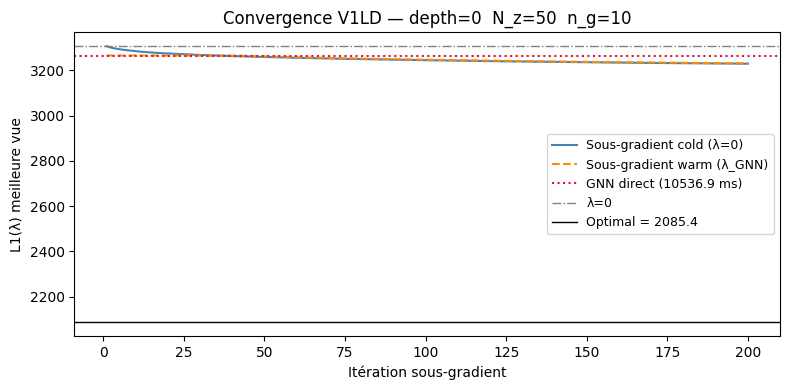


Convergence cold : 200 iters → L1=3229.87
Convergence warm : 200 iters → L1=3231.45


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))

iters = np.arange(1, len(hist_cold) + 1)
ax.plot(iters, hist_cold, color="steelblue", lw=1.5, label="Sous-gradient cold (λ=0)")
ax.plot(np.arange(1, len(hist_warm) + 1), hist_warm,
        color="darkorange", lw=1.5, linestyle="--", label="Sous-gradient warm (λ_GNN)")

ax.axhline(l1_gnn,  color="crimson",  lw=1.5, linestyle=":",  label=f"GNN direct ({t_gnn_total:.1f} ms)")
ax.axhline(l1_zero, color="gray",     lw=1,   linestyle="-.", label="λ=0")

if opt is not None:
    ax.axhline(opt, color="black", lw=1, linestyle="-", label=f"Optimal = {opt:.1f}")

ax.set_xlabel("Itération sous-gradient")
ax.set_ylabel("L1(λ) meilleure vue")
ax.set_title(f"Convergence V1LD — depth={rec['depth'] if 'rec' in dir() else 0}  "
             f"N_z={g_cpu.N_z}  n_g={g_cpu.n_g}")
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f"))
plt.tight_layout()
plt.show()

# Résumé
ref = min(hist_cold[-1], hist_warm[-1])
print(f"\nConvergence cold : {len(hist_cold)} iters → L1={hist_cold[-1]:.2f}")
print(f"Convergence warm : {len(hist_warm)} iters → L1={hist_warm[-1]:.2f}")
if len(hist_warm) < len(hist_cold):
    print(f"Warm-start a converge en {len(hist_warm)/len(hist_cold)*100:.0f}% des itérations du cold start")

## Benchmark d'inférence sur N graphes

In [10]:
N_BENCH = 200   # nombre de graphes à tester

indices = np.random.default_rng(0).choice(len(dataset), N_BENCH, replace=False)

t_fwds, t_totals = [], []
l1_zeros, l1_gnns = [], []

for idx in indices:
    gb = dataset[int(idx)].to(device)

    # L1(λ=0)
    lam0 = torch.zeros(gb.N_z * gb.n_g, device=device)
    with torch.no_grad():
        l1_zeros.append(lagrangian_v1ld(lam0, gb).item())

    # GNN forward
    t0 = time.perf_counter()
    with torch.no_grad(): lam_g = model(gb)
    t_fwds.append((time.perf_counter() - t0) * 1000)

    # GNN + L1
    t0 = time.perf_counter()
    with torch.no_grad():
        lam_g = model(gb)
        l1_gnns.append(lagrangian_v1ld(lam_g, gb).item())
    t_totals.append((time.perf_counter() - t0) * 1000)

t_fwds   = np.array(t_fwds)
t_totals = np.array(t_totals)
l1_zeros = np.array(l1_zeros)
l1_gnns  = np.array(l1_gnns)

print(f"Benchmark sur {N_BENCH} graphes aléatoires\n")
print(f"Forward GNN (ms)       : moy={t_fwds.mean():.2f}  médiane={np.median(t_fwds):.2f}  p95={np.percentile(t_fwds,95):.2f}")
print(f"Forward + L1(GNN) (ms) : moy={t_totals.mean():.2f}  médiane={np.median(t_totals):.2f}  p95={np.percentile(t_totals,95):.2f}")
print()

# Amélioration de GNN vs λ=0
diff = l1_zeros - l1_gnns   # positif = GNN donne une meilleure borne (plus petite)
pct_better = 100 * (diff > 0).mean()
print(f"GNN améliore vs λ=0 : {pct_better:.0f}% des nœuds")
print(f"Amélioration médiane : {np.median(diff):.1f}  (moy={diff.mean():.1f})")

KeyboardInterrupt: 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Distribution des temps
axes[0].hist(t_totals, bins=40, color="steelblue", edgecolor="white", linewidth=0.4)
axes[0].axvline(t_totals.mean(), color="crimson", lw=1.5, linestyle="--",
                label=f"moy={t_totals.mean():.2f} ms")
axes[0].set_xlabel("Temps forward + L1 (ms)")
axes[0].set_ylabel("Fréquence")
axes[0].set_title("Distribution du temps d'inférence")
axes[0].legend()

# GNN vs λ=0
vmin = min(l1_zeros.min(), l1_gnns.min())
vmax = max(l1_zeros.max(), l1_gnns.max())
axes[1].scatter(l1_zeros, l1_gnns, s=8, alpha=0.4, color="steelblue")
axes[1].plot([vmin, vmax], [vmin, vmax], "k--", lw=1, label="y=x")
axes[1].set_xlabel("L1(λ=0)")
axes[1].set_ylabel("L1(λ_GNN)")
axes[1].set_title("Borne GNN vs λ=0  (sous la diagonale = meilleur)")
axes[1].legend()

plt.tight_layout()
plt.show()